### Importing all the files from S1 to S13 into a single DF:

In [13]:
# Imports:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [14]:
# Folder with the CSV files (raw string so the backslashes are read correctly)
data_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\MQ3_logs_S1-S13")

frames = []
skipped = []

for f in sorted(data_dir.glob("*.csv")):   # only files in this folder, not subfolders
    # Split into at most 5 parts, so yt_ext stays intact even if it contains "_"
    parts = f.stem.split("_", 4)
    if len(parts) != 5:
        skipped.append(f.name)
        continue

    set_id, vd_id, init_soc, user_state, yt_ext = parts

    df = pd.read_csv(f)              # e.g. for filename "S12_V2_95_SQ_G-XZhKqQAHU" 
    df["set_id"] = set_id            # e.g. "S12"
    df["vd_id"] = vd_id              # e.g. "V2"
    df["init_soc"] = int(init_soc)   # e.g. 95 (as a number)
    df["user_state"] = user_state    # e.g. "SQ"
    df["yt_ext"] = yt_ext            # e.g. "G-XZhKqQAHU"
    frames.append(df)

df_all = pd.concat(frames, ignore_index=True)

print(f"Loaded {len(frames)} files, {len(df_all)} rows, {df_all.shape[1]} columns")
if skipped:
    print("Skipped (unexpected file name):", skipped)

df_all.head()

Loaded 70 files, 21707 rows, 46 columns


,id_line,Timestamp,Elapsed (s),Level (%),Voltage (mV),Temp (C),Charge Counter (uAh),Calculated Current (mA),Calculated Power (mW),Accumulated Power (mWh),...,Video Clock,Video Session,Video Position (s),Video Position (mm:ss),Position Source,set_id,vd_id,init_soc,user_state,yt_ext
0,30,2026-10-13 18:31:42,29.61,99,4215,32.0,4953606,1701.79,7173.04,74.763,...,Running,1,0.3,00:00,manual clock,S10,V1,100,ST,KGerjHMa90s
1,31,2026-10-13 18:31:43,30.62,99,4215,32.0,4953606,1701.79,7173.04,77.731,...,Running,1,1.3,00:01,manual clock,S10,V1,100,ST,KGerjHMa90s
2,32,2026-10-13 18:31:45,32.11,99,4215,32.0,4953606,1701.79,7173.04,79.405,...,Running,1,2.8,00:02,manual clock,S10,V1,100,ST,KGerjHMa90s
3,33,2026-10-13 18:31:46,32.95,99,4215,32.0,4953606,1701.79,7173.04,81.617,...,Running,1,3.6,00:03,manual clock,S10,V1,100,ST,KGerjHMa90s
4,34,2026-10-13 18:31:47,34.06,99,4215,32.0,4953606,1701.79,7173.04,83.091,...,Running,1,4.7,00:04,manual clock,S10,V1,100,ST,KGerjHMa90s


## Consumption for a single video:

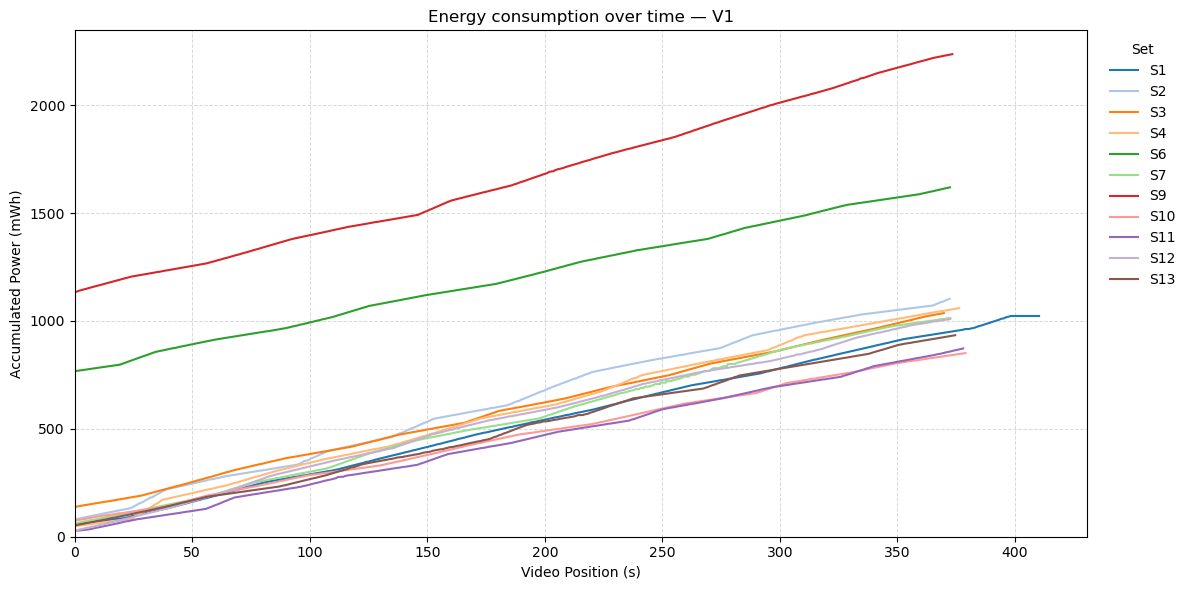

In [15]:
import matplotlib.pyplot as plt

v1 = df_all[df_all["vd_id"] == "V1"]

# Set order numerically (S2 before S10)
sets = sorted(v1["set_id"].unique(), key=lambda s: int(s[1:]))

fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets

for i, s in enumerate(sets):
    d = v1[v1["set_id"] == s]
    ax.plot(d["Video Position (s)"], d["Accumulated Power (mWh)"],
            label=s, color=colors[i % len(colors)], linewidth=1.5)

ax.set_xlabel("Video Position (s)")
ax.set_ylabel("Accumulated Power (mWh)")
ax.set_title("Energy consumption over time — V1")
ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

# Legend outside the plot so it doesn't cover the lines
ax.legend(title="Set", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

fig.tight_layout()
plt.show()

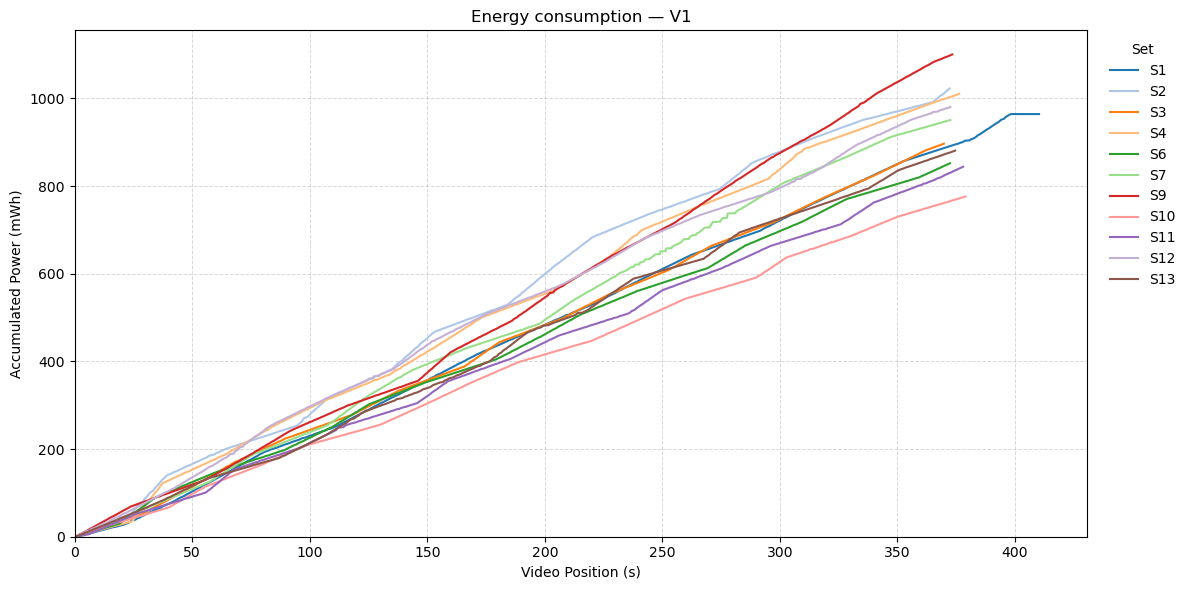

In [16]:
import matplotlib.pyplot as plt

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Set order numerically (S2 before S10)
sets = sorted(v1["set_id"].unique(), key=lambda s: int(s[1:]))

fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets

for i, s in enumerate(sets):
    d = v1[v1["set_id"] == s]
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=s, color=colors[i % len(colors)], linewidth=1.5)

ax.set_xlabel("Video Position (s)")
ax.set_ylabel("Accumulated Power (mWh)")
ax.set_title("Energy consumption — V1")
ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

# Legend outside the plot so it doesn't cover the lines
ax.legend(title="Set", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

fig.tight_layout()
plt.show()

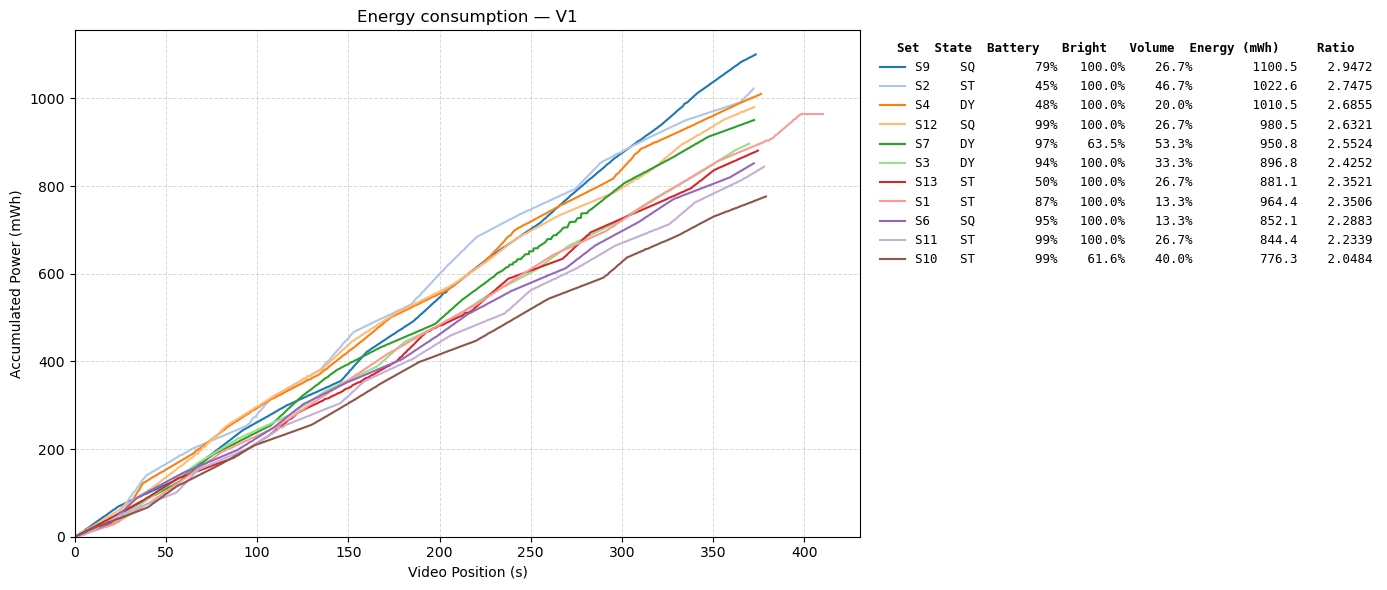

In [17]:
v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Per-set info for the legend
info = v1.groupby("set_id").agg(
    level_max=("Level (%)", "max"),
    user_state=("user_state", "first"),
    bright_avg=("Brightness (%)", "mean"),
    volume_avg=("Volume (%)", "mean"),
    energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
    length_max=("Video Position (s)", "max"),
)

# Ratio: energy per second of video (zero length -> NaN)
info["ratio"] = info["energy"] / info["length_max"].replace(0, np.nan)

# Set order by ratio, highest first
sets = info.sort_values("ratio", ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(14, 6))
colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets

for i, s in enumerate(sets):
    d = v1[v1["set_id"] == s]
    r = info.loc[s]
    label = (f"{s:<4} {r.user_state:^5}  {r.level_max:>6.0f}%  "
             f"{r.bright_avg:>6.1f}%  {r.volume_avg:>6.1f}%  "
             f"{r.energy:>12.1f}  {r.ratio:>8.4f}")
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=label, color=colors[i % len(colors)], linewidth=1.5)

ax.set_xlabel("Video Position (s)")
ax.set_ylabel("Accumulated Power (mWh)")
ax.set_title("Energy consumption — V1")
ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

# Legend outside the plot, monospace so the columns align
header = (f"{'Set':<4} {'State':^5}  {'Battery':>7}  {'Bright':>7}  "
          f"{'Volume':>7}  {'Energy (mWh)':>12}  {'Ratio':>8}")
ax.legend(title=header, bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False,
          prop={"family": "monospace", "size": 9},
          title_fontproperties={"family": "monospace", "size": 9, "weight": "bold"})

fig.tight_layout()
plt.show()

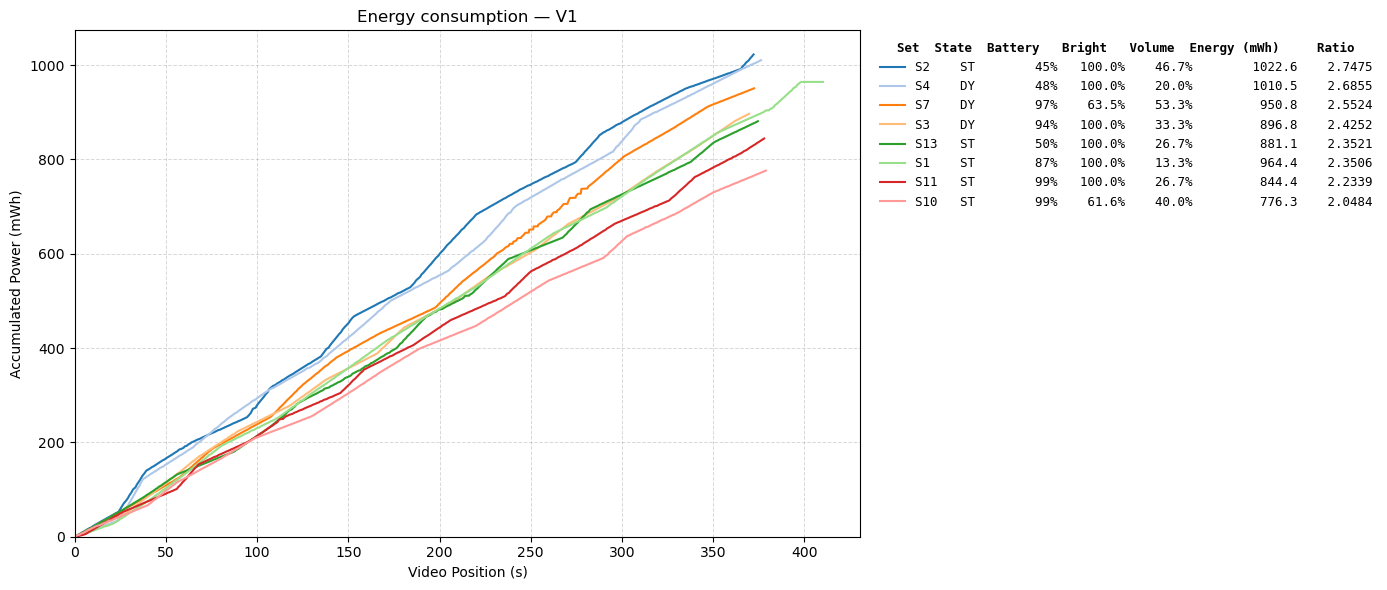

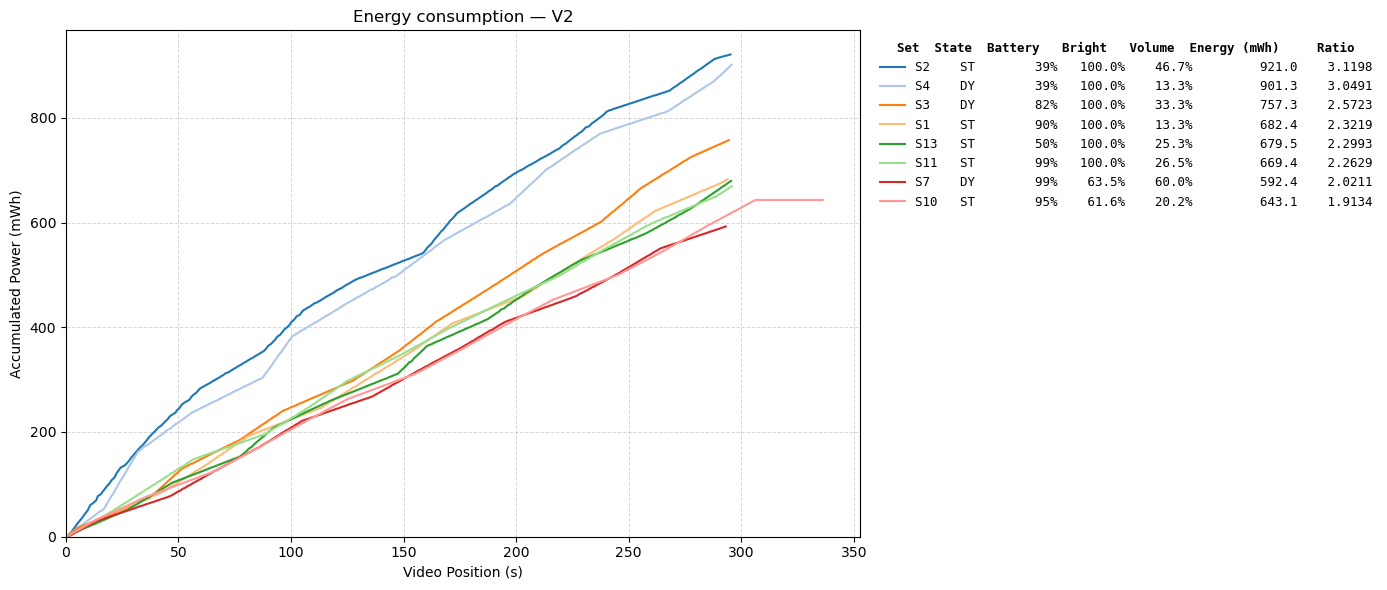

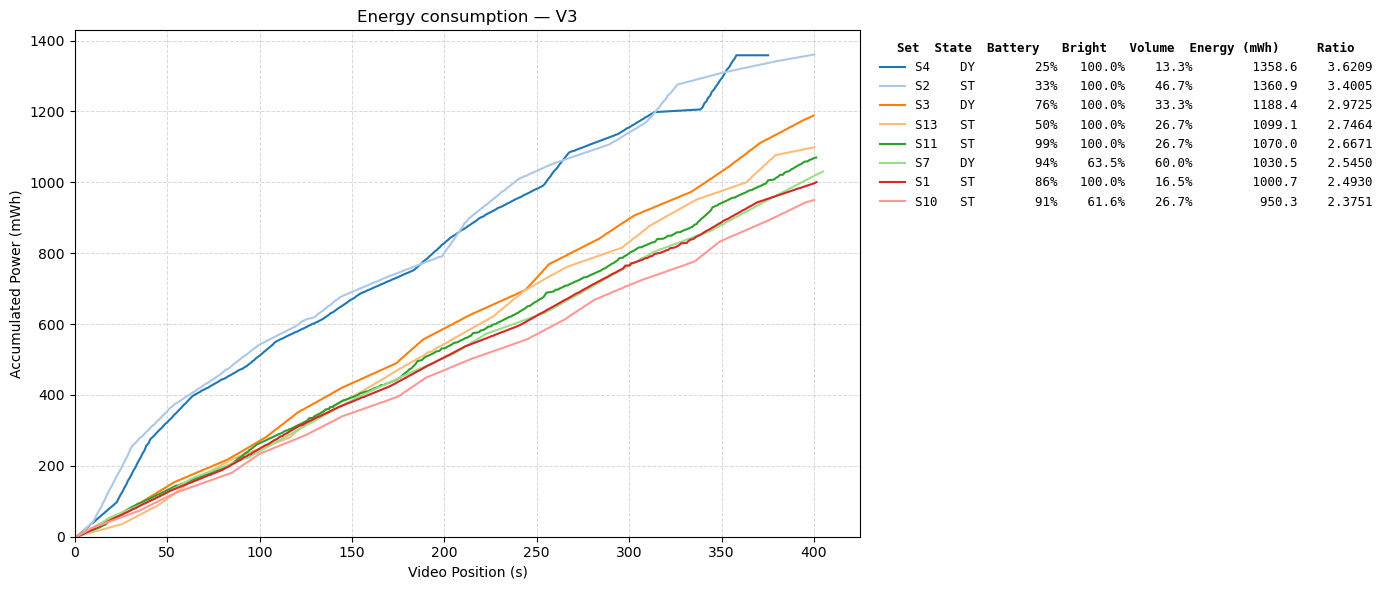

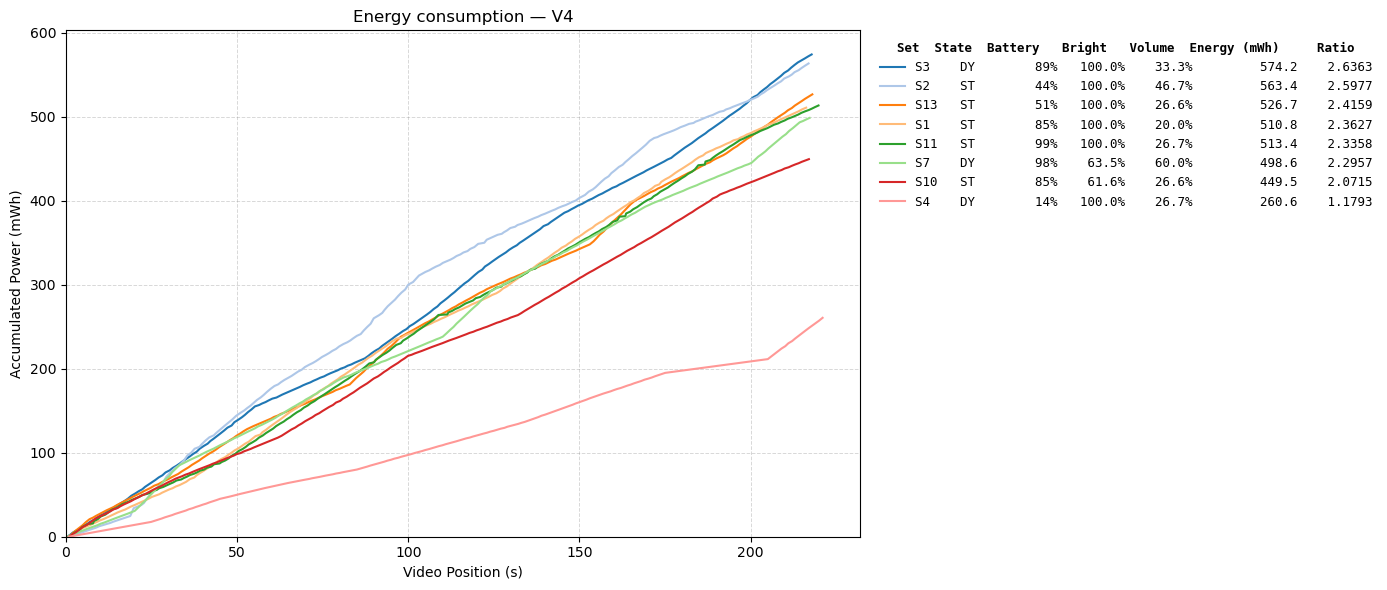

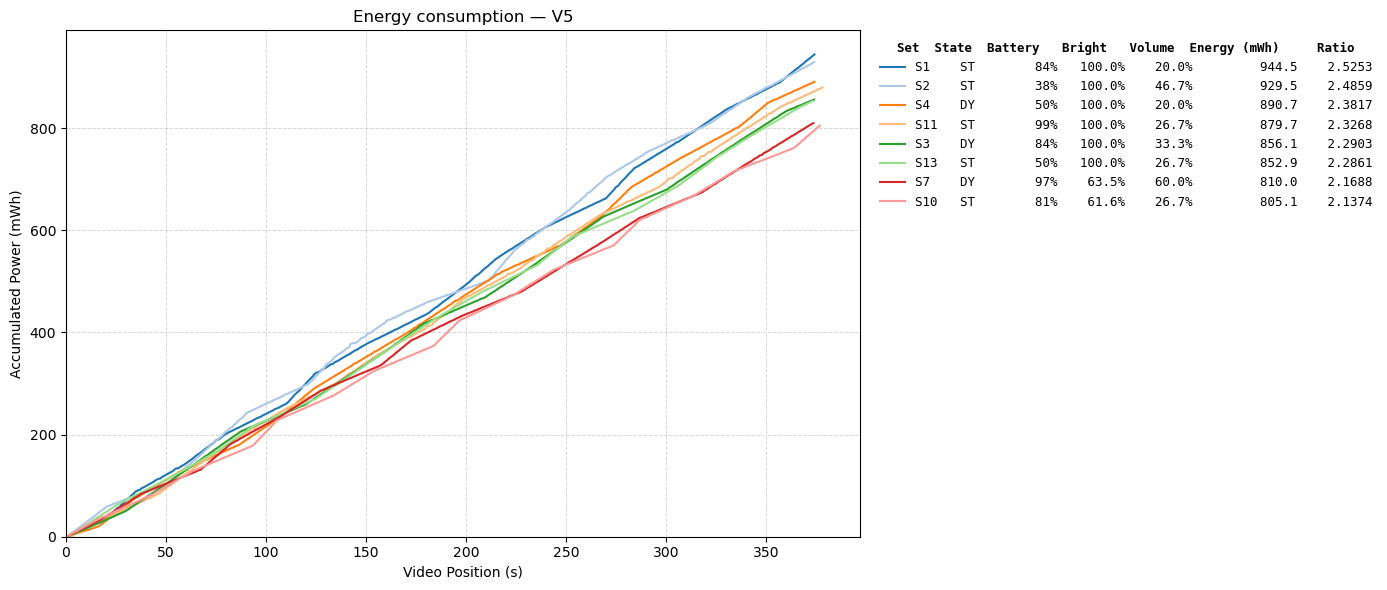

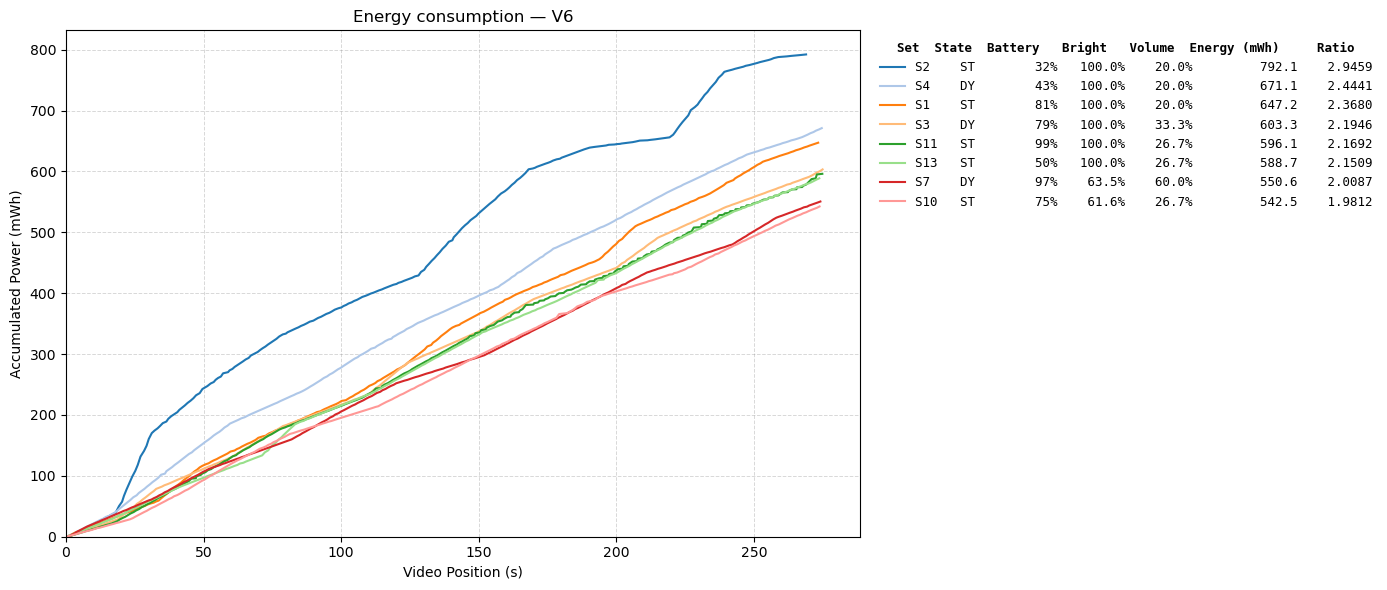

In [18]:
import matplotlib.pyplot as plt
import numpy as np

def plot_video(vd):
    """Accumulated power over video position for one video, one line per set."""
    v = df_all[(df_all["vd_id"] == vd) & (df_all["user_state"] != "SQ")].copy()
    if v.empty:
        print(f"No data for {vd}")
        return

    # Shift each set's accumulated power so its first value is 0
    v["Accumulated Power from start (mWh)"] = (
        v["Accumulated Power (mWh)"]
        - v.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
    )

    # Per-set info for the legend
    info = v.groupby("set_id").agg(
        level_max=("Level (%)", "max"),
        user_state=("user_state", "first"),
        bright_avg=("Brightness (%)", "mean"),
        volume_avg=("Volume (%)", "mean"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        length_max=("Video Position (s)", "max"),
    )

    # Ratio: energy per second of video (zero length -> NaN)
    info["ratio"] = info["energy"] / info["length_max"].replace(0, np.nan)

    # Set order by ratio, highest first
    sets = info.sort_values("ratio", ascending=False).index.tolist()

    fig, ax = plt.subplots(figsize=(14, 6))
    colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets

    for i, s in enumerate(sets):
        d = v[v["set_id"] == s]
        r = info.loc[s]
        label = (f"{s:<4} {r.user_state:^5}  {r.level_max:>6.0f}%  "
                 f"{r.bright_avg:>6.1f}%  {r.volume_avg:>6.1f}%  "
                 f"{r.energy:>12.1f}  {r.ratio:>8.4f}")
        ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
                label=label, color=colors[i % len(colors)], linewidth=1.5)

    ax.set_xlabel("Video Position (s)")
    ax.set_ylabel("Accumulated Power (mWh)")
    ax.set_title(f"Energy consumption — {vd}")
    ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    # Legend outside the plot, monospace so the columns align
    header = (f"{'Set':<4} {'State':^5}  {'Battery':>7}  {'Bright':>7}  "
              f"{'Volume':>7}  {'Energy (mWh)':>12}  {'Ratio':>8}")
    ax.legend(title=header, bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False,
              prop={"family": "monospace", "size": 9},
              title_fontproperties={"family": "monospace", "size": 9, "weight": "bold"})

    fig.tight_layout()

    out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
    out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

    fig.savefig(out_dir / f"Energy_consumption_graph_{vd}.pdf", dpi=300, bbox_inches="tight")

    plt.show()


# One graph per video, V1 to V6
videos = sorted(df_all["vd_id"].unique(), key=lambda v: int(v[1:]))
for vd in videos:
    plot_video(vd)